In [ ]:
import time
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import kagglehub
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
from sklearn.metrics import f1_score
from collections import Counter

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

In [ ]:

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)), # рандомно вырезает кусок площадью от 70% до 100% от оригинала. итоговый размер изображения 224 на 224
    transforms.RandomHorizontalFlip(),  #  с вероятностью 50% отражает картинку
    transforms.RandomRotation(10), # случайно поворачивает картинку от -10 до +10 градусов
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2), # делает картинку светлее или темнее на 20%, меняет контрастность, насыщенность цвета
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)), # случайно сдвигает изображение по горизонтали и вертикали до 10%
    transforms.ToTensor(),                              # из [0, 255] делаем [0, 1]
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])]) # делаем из [0, 1] [-1, 1]

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])])

batch_size = 32

base_path_str = kagglehub.dataset_download("asdasdasasdas/garbage-classification")
base_path = Path(base_path_str)
root = base_path / "Garbage classification" / "Garbage classification"

train_base = datasets.ImageFolder(root=root, transform=train_transform) # присваиваем метки
eval_base  = datasets.ImageFolder(root=root, transform=eval_transform)
assert train_base.classes == eval_base.classes

# разбиваем датасет в формате 70/15/15 с фиксированным seed
g = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(train_base), generator=g).tolist() # рандомно формирует список индексов
n_total = len(indices)
n_train = int(0.70 * n_total)
n_val   = int(0.15 * n_total)

train_idx = indices[:n_train] # индексы формируем
val_idx   = indices[n_train:n_train + n_val]
test_idx  = indices[n_train + n_val:]

from torch.utils.data import Subset
train_set = Subset(train_base, train_idx)
valid_set = Subset(eval_base,  val_idx)
test_set  = Subset(eval_base,  test_idx)

train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True,  num_workers=2)
valid_loader = DataLoader(valid_set, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_set,  batch_size=batch_size, shuffle=False, num_workers=2) # num_workers=2 это число потоков, готовящих следующий бач

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Всего изображений: {len(train_base)}")
print(f"  train: {len(train_set)}  |  valid: {len(valid_set)}  |  test: {len(test_set)}")
print(f"Классы ({len(train_base.classes)}): {train_base.classes}")

sample_img, sample_label = eval_base[0]
print(f"Форма изображения: {tuple(sample_img.shape)}")
print(f"Форма метки: {tuple(torch.tensor(sample_label).shape)} (значение: {sample_label})")
print(f"Устройство: {device}")

Using Colab cache for faster access to the 'garbage-classification' dataset.
Всего изображений: 2527
  train: 1768  |  valid: 379  |  test: 380
Классы (6): ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Форма изображения: (3, 224, 224)
Форма метки: () (значение: 0)
Устройство: cuda


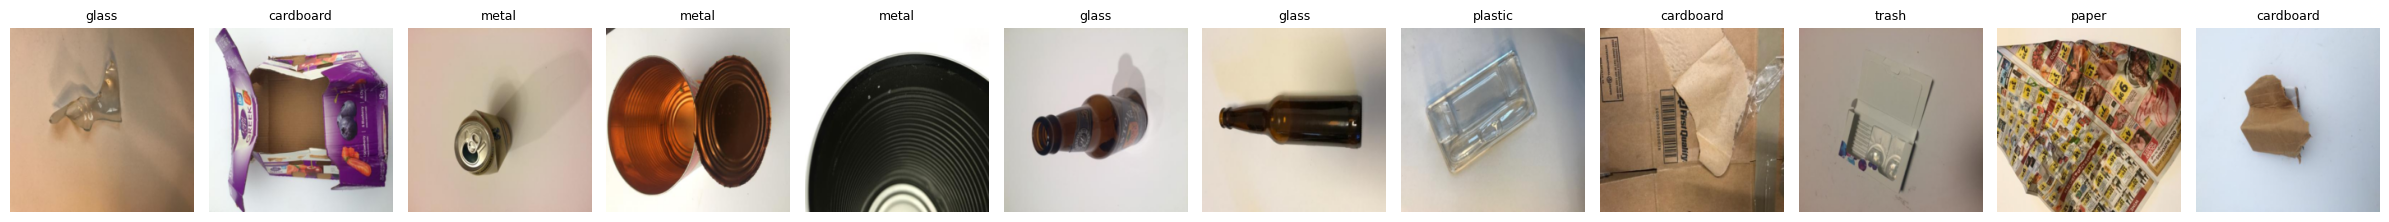

In [ ]:
mean, std = [0.5, 0.5, 0.5], [0.5, 0.5, 0.5]

def show_images(dataset, num_images=12):
    plt.figure(figsize=(2 * num_images, 3))
    indices = random.sample(range(len(dataset)), num_images)
    for i, r in enumerate(indices):
        img, label = dataset[r]
        img = img.permute(1, 2, 0).numpy()
        img = std * img + mean
        img = np.clip(img, 0, 1)
        plt.subplot(1, num_images, i + 1)
        plt.imshow(img)
        plt.title(dataset.classes[label], fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

show_images(eval_base)

In [ ]:
num_classes = len(train_base.classes)
dropout_ = 0.5

def _add_bn_to_vgg_features(features: nn.Sequential) -> nn.Sequential:
    """Вставляет BatchNorm2d после каждого Conv2d (перед ReLU)."""
    new_layers = []
    for layer in features:
        new_layers.append(layer)
        if isinstance(layer, nn.Conv2d):
            new_layers.append(nn.BatchNorm2d(layer.out_channels))
    return nn.Sequential(*new_layers)

def vgg16_random(num_classes):
    model = models.vgg16(weights=None) # создаем vgg16 из torchvision с, веса модели иниц. случайно
    #model.features = _add_bn_to_vgg_features(model.features)  # Вставляем BatchNorm2d после каждой свёртки
    model.classifier[6] = nn.Sequential( # по умолчанию последний полносвязный слой (индекс 6) выдает 1000 классов, поэтому меняем его на слой, выдающий 6 классов
        nn.Dropout(dropout_),
        nn.Linear(model.classifier[6].in_features, num_classes))
    for p in model.parameters(): # градиенты будут считаться для всех слоев, так как модель учится с нуля
        p.requires_grad = True
    return model

def vgg16_transfer(num_classes):
    model = models.vgg16(weights=models.VGG16_Weights.DEFAULT) # ставим предобученные веса
    for p in model.parameters(): # не обучаем предобученные веса
        p.requires_grad = False
    model.classifier = nn.Sequential( # создаем свой классификатор
        nn.Linear(512 * 7 * 7, 512), # сжимаем до 512 нейронов
        nn.BatchNorm1d(512),
        nn.ReLU(),
        nn.Dropout(dropout_),
        nn.Linear(512, num_classes))
    return model


def resnet_50_random(num_classes):
    model = models.resnet50(weights=None) # веса модели иниц. случайно
    in_features = model.fc.in_features # число входных признаков у финального слоя (2048)
    model.fc = nn.Sequential(
        nn.Dropout(dropout_),
        nn.Linear(in_features, num_classes))  # берёт 2048 признаков и выдаёт 1 из 6 классов
    for p in model.parameters():  # градиенты будут считаться для всех слоев, так как модель учится с нуля
        p.requires_grad = True
    return model


def resnet_50_transfer(num_classes):
    model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    for p in model.parameters(): # не обучаем предобученные веса
        p.requires_grad = False
    in_features = model.fc.in_features # число входных признаков у финального слоя (2048)
    model.fc = nn.Sequential(  # создаем свой классификатор
        nn.Linear(in_features, 512), # берёт 2048 признаков и выделяет 512 (для борьбы с переобучением)
        nn.ReLU(),
        nn.Linear(512, num_classes))
    return model


def efficientnet_b0_random(num_classes):
    model = models.efficientnet_b0(weights=None)
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Sequential(
        nn.Dropout(dropout_),
        nn.Linear(in_features, num_classes),
    )
    for p in model.parameters():
        p.requires_grad = True
    return model


def efficientnet_b0_transfer(num_classes):
    model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
    for p in model.parameters():
        p.requires_grad = False
    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(0.3),
        nn.Linear(in_features, 512),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(512, num_classes),
    )
    return model


def googlenet_random(num_classes):
    model = models.googlenet(weights=None, init_weights=True, aux_logits=False)
    in_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Dropout(dropout_),
        nn.Linear(in_features, num_classes),
    )
    for p in model.parameters():
        p.requires_grad = True
    return model


def googlenet_transfer(num_classes):
    model = models.googlenet(weights=models.GoogLeNet_Weights.DEFAULT, aux_logits=True)
    for p in model.parameters():
        p.requires_grad = False
    in_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Linear(in_features, 512),
        nn.ReLU(),
        nn.Linear(512, num_classes),
    )
    model.aux_logits = False
    model.aux1 = None
    model.aux2 = None
    return model

In [ ]:
num_classes = len(train_base.classes)

# частоты классов в тренировочной выборке
train_labels = [train_base.samples[i][1] for i in train_idx]
counts = Counter(train_labels)
class_counts = torch.tensor([counts[i] for i in range(num_classes)], dtype=torch.float32)

# веса обратно пропорциональны частоте, нормированы
class_weights = class_counts.sum() / (num_classes * class_counts)
class_weights = class_weights.to(device)

print("Веса классов:", {train_base.classes[i]: round(class_weights[i].item(), 3) for i in range(num_classes)})

loss_function = nn.CrossEntropyLoss(weight=class_weights).to(device)


def train(model, optimizer):
    model.train()
    train_loss, train_accuracy = [], []
    start = time.time()
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = loss_function(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss.append(loss.item())
        train_accuracy.append((outputs.argmax(1) == labels).float().mean().item())
    return np.mean(train_loss), np.mean(train_accuracy), time.time() - start


def valid(model):
    model.eval()
    losses, accs, f1s = [], [], []
    start = time.time()
    with torch.no_grad():
        for images, labels in valid_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            losses.append(loss_function(outputs, labels).item())
            accs.append((outputs.argmax(1) == labels).float().mean().item())
            f1s.append(f1_score(labels.cpu(), outputs.argmax(1).cpu(), average="macro"))
    return np.mean(losses), np.mean(accs), time.time() - start, np.mean(f1s)


def test(model):
    model.eval()
    f1s, accs = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            f1s.append(f1_score(labels.cpu(), outputs.argmax(1).cpu(), average="macro"))
            accs.append((outputs.argmax(1) == labels).float().mean().item())
    return np.mean(f1s), np.mean(accs)


def experiment(model, epochs, learning_rate):
    f1_valid = []
    optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    for epoch in range(epochs):
        print(f"\tEpoch: {epoch + 1}/{epochs}", end=". ")
        tr_loss, tr_acc, tr_time = train(model, optimizer)
        print(f"Train loss: {tr_loss:.3f}, acc: {tr_acc:.3f}, time: {tr_time:.2f}s", end=". ")
        va_loss, va_acc, va_time, va_f1 = valid(model)
        print(f"Validation loss: {va_loss:.3f}, acc: {va_acc:.3f}, time: {va_time:.2f}s, f1: {va_f1:.3f}")
        f1_valid.append(va_f1)
        scheduler.step()

    test_f1, test_acc = test(model)
    print(f"Test f1: {test_f1:.3f} (acc: {test_acc:.3f})")
    return f1_valid, test_f1

Веса классов: {'cardboard': 1.016, 'glass': 0.828, 'metal': 1.049, 'paper': 0.703, 'plastic': 0.885, 'trash': 3.311}


In [ ]:
expected_models = [
    {'name': 'VGG-16 random',          'function': vgg16_random,           'epochs': 15, 'lr': 1e-4, 'color': 'forestgreen'},
    {'name': 'VGG-16 transfer',        'function': vgg16_transfer,         'epochs': 15, 'lr': 0.001, 'color': 'forestgreen'}, # 0.005
    {'name': 'ResNet50 random',        'function': resnet_50_random,       'epochs': 20, 'lr': 0.001, 'color': 'gold'},
    {'name': 'ResNet50 transfer',      'function': resnet_50_transfer,     'epochs': 20, 'lr': 0.001, 'color': 'gold'},
    {'name': 'EfficientNet-B0 random', 'function': efficientnet_b0_random, 'epochs': 30, 'lr': 0.001, 'color': 'darkred'},
    {'name': 'EfficientNet-B0 transfer','function': efficientnet_b0_transfer,'epochs': 30, 'lr': 0.001, 'color': 'darkred'},
    {'name': 'GoogLeNet random',       'function': googlenet_random,       'epochs': 30, 'lr': 0.001, 'color': 'darkblue'},
    {'name': 'GoogLeNet transfer',     'function': googlenet_transfer,     'epochs': 30, 'lr': 0.001, 'color': 'darkblue'},
]

for em in expected_models:
    model = em['function'](num_classes).to(device)
    print(f"Model: {em['name']}")
    em['f1_valid'], em['f1'] = experiment(model, em['epochs'], em['lr'])

Model: VGG-16 random
	Epoch: 1/15. Train loss: 1.794, acc: 0.211, time: 33.51s. Validation loss: 1.784, acc: 0.255, time: 3.22s, f1: 0.120
	Epoch: 2/15. Train loss: 1.770, acc: 0.216, time: 31.68s. Validation loss: 1.745, acc: 0.206, time: 2.46s, f1: 0.133
	Epoch: 3/15. Train loss: 1.705, acc: 0.268, time: 32.04s. Validation loss: 1.729, acc: 0.315, time: 2.55s, f1: 0.200
	Epoch: 4/15. Train loss: 1.631, acc: 0.309, time: 31.93s. Validation loss: 1.655, acc: 0.315, time: 2.51s, f1: 0.199
	Epoch: 5/15. Train loss: 1.617, acc: 0.304, time: 32.02s. Validation loss: 1.527, acc: 0.341, time: 2.50s, f1: 0.271
	Epoch: 6/15. Train loss: 1.549, acc: 0.352, time: 32.06s. Validation loss: 1.529, acc: 0.357, time: 3.05s, f1: 0.265
	Epoch: 7/15. Train loss: 1.503, acc: 0.395, time: 31.87s. Validation loss: 1.394, acc: 0.444, time: 2.52s, f1: 0.400
	Epoch: 8/15. Train loss: 1.455, acc: 0.424, time: 31.96s. Validation loss: 1.452, acc: 0.403, time: 2.53s, f1: 0.345
	Epoch: 9/15. Train loss: 1.410, ac

/usr/local/lib/python3.13/dist-packages/torchvision/models/googlenet.py:341: UserWarning: auxiliary heads in the pretrained googlenet model are NOT pretrained, so make sure to train them
  warnings.warn(


Train loss: 1.336, acc: 0.506, time: 12.51s. Validation loss: 0.880, acc: 0.713, time: 1.74s, f1: 0.675
	Epoch: 2/30. Train loss: 0.865, acc: 0.707, time: 12.67s. Validation loss: 0.800, acc: 0.697, time: 2.25s, f1: 0.661
	Epoch: 3/30. Train loss: 0.824, acc: 0.717, time: 12.48s. Validation loss: 0.746, acc: 0.718, time: 2.73s, f1: 0.679
	Epoch: 4/30. Train loss: 0.731, acc: 0.732, time: 12.74s. Validation loss: 0.658, acc: 0.734, time: 1.88s, f1: 0.700
	Epoch: 5/30. Train loss: 0.724, acc: 0.742, time: 12.91s. Validation loss: 0.791, acc: 0.690, time: 1.79s, f1: 0.661
	Epoch: 6/30. Train loss: 0.712, acc: 0.745, time: 12.86s. Validation loss: 0.776, acc: 0.716, time: 1.78s, f1: 0.670
	Epoch: 7/30. Train loss: 0.671, acc: 0.759, time: 12.48s. Validation loss: 0.587, acc: 0.798, time: 1.71s, f1: 0.761
	Epoch: 8/30. Train loss: 0.612, acc: 0.776, time: 11.94s. Validation loss: 0.645, acc: 0.750, time: 1.71s, f1: 0.711
	Epoch: 9/30. Train loss: 0.625, acc: 0.783, time: 11.96s. Validation 

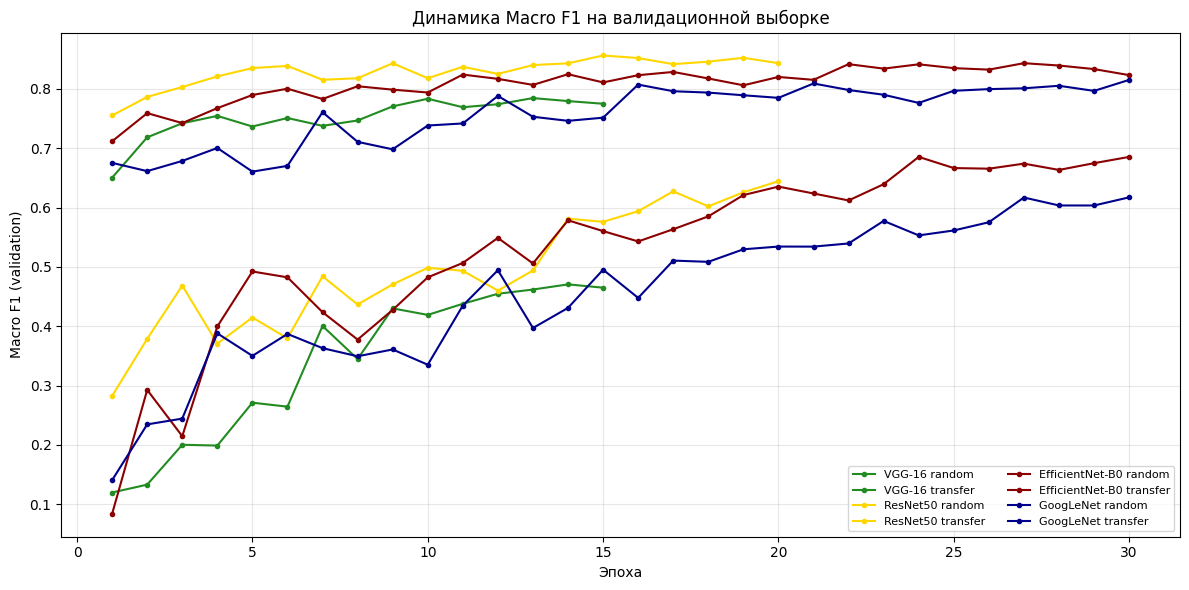

In [ ]:
plt.figure(figsize=(12, 6))
for em in expected_models:
    plt.plot(range(1, em['epochs'] + 1), em['f1_valid'],
             marker='o', markersize=3, color=em['color'], label=em['name'])
plt.xlabel("Эпоха")
plt.ylabel("Macro F1 (validation)")
plt.title("Динамика Macro F1 на валидационной выборке")
plt.grid(alpha=0.3)
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()


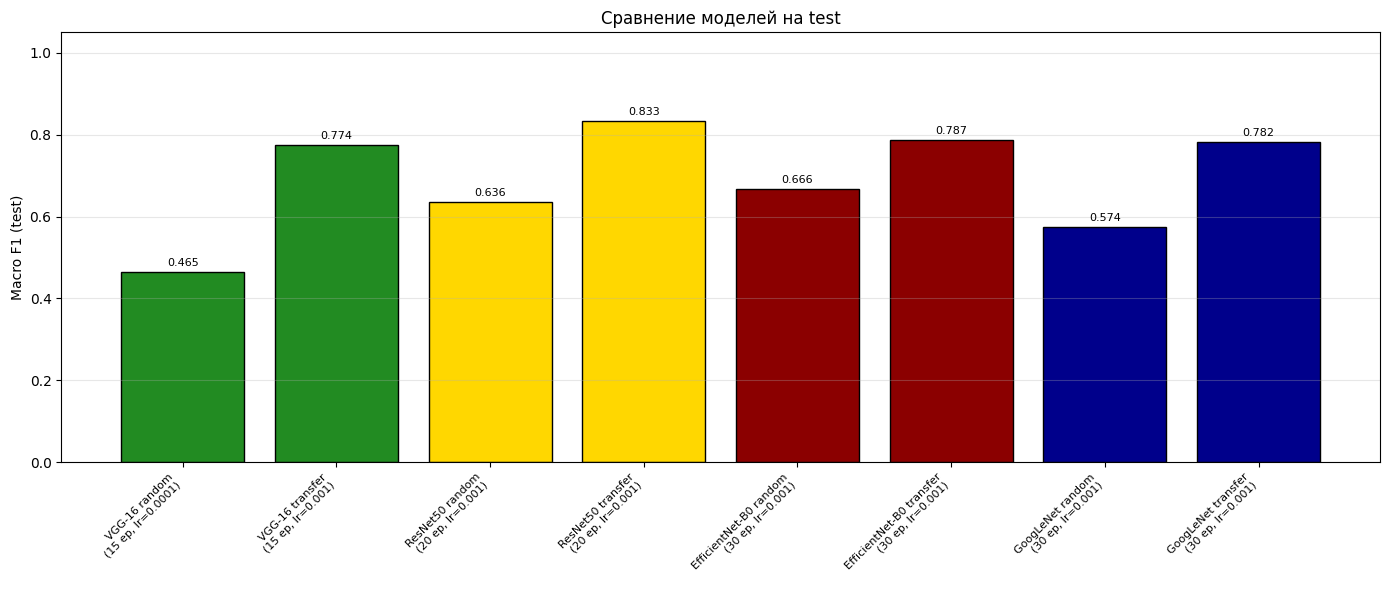

In [ ]:
labels  = [f"{em['name']}\n({em['epochs']} ep, lr={em['lr']})" for em in expected_models]
scores  = [em['f1'] for em in expected_models]
colors  = [em['color'] for em in expected_models]

plt.figure(figsize=(14, 6))
bars = plt.bar(range(len(labels)), scores, color=colors, edgecolor='black')
plt.xticks(range(len(labels)), labels, rotation=45, ha='right', fontsize=8)
plt.ylabel("Macro F1 (test)")
plt.title("Сравнение моделей на test")
plt.ylim(0, 1.05)
plt.grid(axis='y', alpha=0.3)
for bar, s in zip(bars, scores):
    plt.text(bar.get_x() + bar.get_width() / 2, s + 0.01, f"{s:.3f}",
             ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Всего параметров:      {total:,}")
    print(f"Обучаемых параметров:  {trainable:,} ({trainable / total * 100:.2f}%)")

print(f"{'Модель':<25} | {'Всего':<14} | {'Обучаемых':<14} | {'% обучаемых'}")
print()
for em in expected_models:
    # Создаём модель через функцию из словаря
    model = em['function'](num_classes)

    # Считаем параметры
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    percent = (trainable / total) * 100

    # Выводим строку
    print(f"{em['name']:<25} | {total:<14,} | {trainable:<14,} | {percent:.2f}%")

    # (Опционально) очищаем память, чтобы не забить GPU, если моделей много
    del model
    torch.cuda.empty_cache() if torch.cuda.is_available() else None


Модель                    | Всего          | Обучаемых      | % обучаемых

VGG-16 random             | 134,285,126    | 134,285,126    | 100.00%
VGG-16 transfer           | 27,564,358     | 12,849,670     | 46.62%
ResNet50 random           | 23,520,326     | 23,520,326     | 100.00%
ResNet50 transfer         | 23,520,326     | 12,294         | 0.05%
GoogLeNet random          | 5,606,054      | 5,606,054      | 100.00%


/usr/local/lib/python3.13/dist-packages/torchvision/models/googlenet.py:341: UserWarning: auxiliary heads in the pretrained googlenet model are NOT pretrained, so make sure to train them
  warnings.warn(


GoogLeNet transfer        | 5,606,054      | 6,150          | 0.11%
EfficientNet-B0 random    | 4,015,234      | 4,015,234      | 100.00%
EfficientNet-B0 transfer  | 4,015,234      | 7,686          | 0.19%
